In [1]:
import pandas as pd

df = pd.read_csv("venom-dataset-summary.csv", sep=";", decimal=",")
print(df.shape)
print(df["comment"].notna().sum())

(196591, 9)
19464


In [2]:
ok = df[df["comment"].isna()]
print(len(ok))                                    # paper: 177,127

with_addr = ok[ok["btc_addrs_count"] > 0]
print(len(with_addr))                             # paper: 13,154 (7.4 %)

print((with_addr["n_tx"] > 0).sum())              # paper: 2,463
print((with_addr["btc_addrs_count"] == 1).sum())  # paper: 11,328 (86.1 %)
print(with_addr["btc_addrs_count"].max())         # paper: 2,028

177127
13154
2463
11328
2028.0


In [3]:
import ast

ok = ok.copy()
ok["addr_list"] = ok["btc_addrs"].fillna("[]").apply(ast.literal_eval)

all_addrs = ok["addr_list"].explode().dropna()
print(len(all_addrs))                         # address occurrences, duplicates included
print(all_addrs.nunique())                    # unique addresses
print(all_addrs.value_counts().head(5).tolist())  # on how many sites do the most-shared addresses appear?

25070
4382
[1648, 1648, 1648, 127, 125]


In [4]:
has_addr = ok[ok["addr_list"].str.len() > 0].copy()
has_addr["addr_key"] = has_addr["addr_list"].apply(lambda l: tuple(sorted(l)))

clusters = has_addr.groupby("addr_key").agg(
    n_sites=("onion_addr", "size"),
    n_tx=("n_tx", "first"),
    n_tx_values=("n_tx", "nunique"),
)

print(len(has_addr), len(clusters))                    # sites with addresses / distinct address sets
print((clusters["n_tx_values"] > 1).sum())             # clusters with inconsistent n_tx (expect 0)
print(clusters["n_sites"].sort_values(ascending=False).head(10).tolist())
print((clusters["n_sites"] == 1).sum())                # clusters made of a single site

13154 686
0
[1648, 127, 125, 119, 113, 109, 109, 109, 107, 106]
318


In [5]:
# 1. sites vs clusters with at least one transaction
print((has_addr["n_tx"] > 0).sum(), (clusters["n_tx"] > 0).sum())    # paper: 2,463 sites

# 2. share of all transactions held by the top 4 (sites, then clusters)
site_tx = has_addr["n_tx"].fillna(0).sort_values(ascending=False)
print(site_tx.head(4).sum() / site_tx.sum())                          # paper: > 0.95

cluster_tx = clusters["n_tx"].fillna(0).sort_values(ascending=False)
print(cluster_tx.head(4).sum() / cluster_tx.sum())

# 3. the biggest mirror cluster (no addresses printed)
top_key = clusters["n_sites"].idxmax()
sub = has_addr[has_addr["addr_key"] == top_key]
print(len(sub), sub["n_tx"].iloc[0], sub["total_received"].iloc[0], len(top_key))

2463 292
0.9571207341478217
0.9751971814271984
1648 7.0 10.77 3


In [6]:
t = ok[["topic", "title"]].dropna(subset=["topic"]).copy()
t["topic"] = t["topic"].str.split(", ")
t = t.explode("topic")

summary = t.groupby("topic").agg(
    n_sites=("title", "size"),
    n_distinct_titles=("title", "nunique"),
)
summary["pct_of_reached_sites"] = (summary["n_sites"] / len(ok) * 100).round(1)
print(summary.sort_values("n_sites", ascending=False))

                   n_sites  n_distinct_titles  pct_of_reached_sites
topic                                                              
stolen_funds        109169                891                  61.6
abusive_content      30955               1991                  17.5
market               27921                921                  15.8
pornography          27254               2002                  15.4
website_list          8460               1205                   4.8
other                 6751               2977                   3.8
hacking               4215                389                   2.4
stolen_bitcoin        3412                111                   1.9
bitcoin_generator      257                 61                   0.1
bitcoin_mixer          200                 61                   0.1


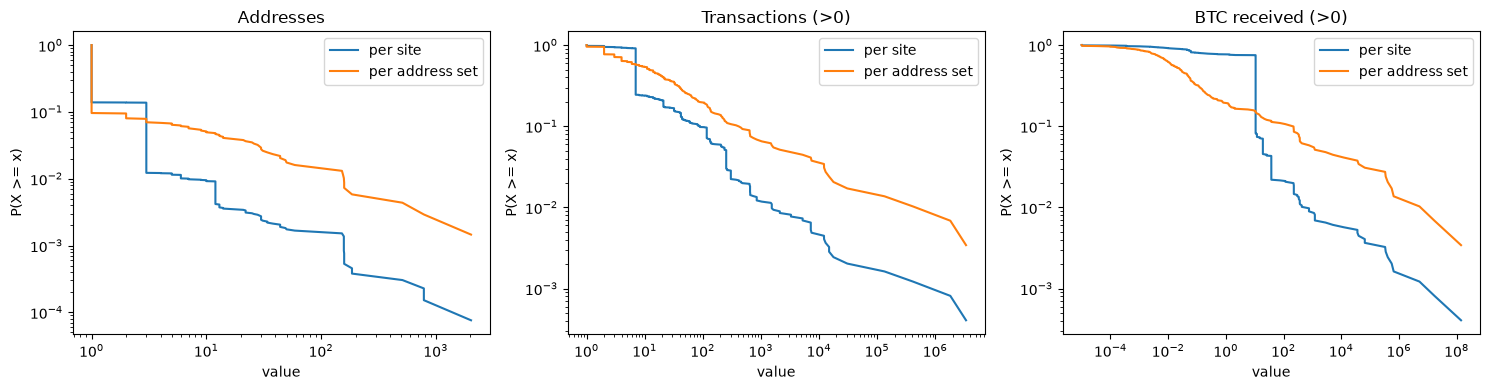

In [7]:
import numpy as np
import matplotlib.pyplot as plt

clusters = has_addr.groupby("addr_key").agg(
    n_sites=("onion_addr", "size"),
    n_addr=("btc_addrs_count", "first"),
    n_tx=("n_tx", "first"),
    total_received=("total_received", "first"),
)

def ccdf(values):
    v = np.sort(np.asarray(values))
    p = 1.0 - np.arange(len(v)) / len(v)   # share with value >= v[i]
    return v, p

panels = [
    ("Addresses", has_addr["btc_addrs_count"], clusters["n_addr"]),
    ("Transactions (>0)", has_addr.loc[has_addr["n_tx"] > 0, "n_tx"],
                          clusters.loc[clusters["n_tx"] > 0, "n_tx"]),
    ("BTC received (>0)", has_addr.loc[has_addr["total_received"] > 0, "total_received"],
                          clusters.loc[clusters["total_received"] > 0, "total_received"]),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, site_vals, set_vals) in zip(axes, panels):
    for vals, label in [(site_vals, "per site"), (set_vals, "per address set")]:
        x, p = ccdf(vals.dropna())
        ax.loglog(x, p, label=label)
    ax.set_title(title); ax.set_xlabel("value"); ax.set_ylabel("P(X >= x)"); ax.legend()
plt.tight_layout()
plt.show()

In [11]:
MIN_TX, MAX_TX, MAX_ADDR = 20, 5000, 10

# 1. sanity check: total_received should be identical within each address set
print(has_addr.groupby("addr_key")["total_received"].nunique().max())   # expect 1

# 2. topics per address set
topics_per_cluster = (
    has_addr.assign(topic_list=has_addr["topic"].fillna("").str.split(", "))
    .groupby("addr_key")["topic_list"]
    .apply(lambda s: sorted({t for lst in s for t in lst if t}))
)
cand = clusters.join(topics_per_cluster.rename("topics")).reset_index()
cand["cluster_id"] = cand.index

# 3. exclude noisy sensitive labels
bad = cand["topics"].apply(lambda t: "abusive_content" in t or "pornography" in t)
cand = cand[~bad]

# 4. keep clusters with a manageable history
pool = cand[(cand["n_tx"] >= MIN_TX) & (cand["n_tx"] <= MAX_TX) & (cand["n_addr"] <= MAX_ADDR)]
print(len(cand), len(pool))
print(pool["topics"].explode().value_counts())

# 5. one cluster per topic: the busiest one
by_topic = pool.explode("topics").sort_values("n_tx", ascending=False)
by_topic = by_topic[by_topic["topics"].notna() & (by_topic["topics"] != "other")]
top_ids = by_topic.drop_duplicates("topics")["cluster_id"].unique()
selected = pool[pool["cluster_id"].isin(top_ids)].copy()

print(len(selected))
print(selected[["cluster_id", "topics", "n_sites", "n_addr", "n_tx"]])
print(selected["n_tx"].sum() / 25)   # rough number of API requests (assumes ~25 tx per page, unverified)

1
591 83
topics
bitcoin_generator    27
stolen_funds         26
other                22
market               20
stolen_bitcoin       18
hacking              11
website_list         10
bitcoin_mixer         3
Name: count, dtype: int64
6
     cluster_id                                             topics  n_sites  \
25           25                  [bitcoin_generator, stolen_funds]        2   
43           43             [hacking, market, other, stolen_funds]        9   
149         149  [bitcoin_generator, market, other, stolen_bitc...        3   
157         157                              [other, website_list]       16   
209         209                                   [stolen_bitcoin]        1   
667         667                                    [bitcoin_mixer]        2   

     n_addr    n_tx  
25      3.0  2118.0  
43      1.0    89.0  
149     1.0   262.0  
157     1.0   304.0  
209     1.0  1645.0  
667     1.0   456.0  
194.96


In [12]:
selected = pool[pool["cluster_id"].isin(top_ids) | pool["topics"].apply(lambda t: "bitcoin_mixer" in t)].copy()

In [13]:
import os
os.makedirs("data", exist_ok=True)
selected.to_pickle("data/selected_clusters.pkl")